In [46]:
import pandas as pd
import matplotlib.pyplot as plt

In [29]:
df = pd.read_csv('../data/raw/diamonds.csv')

In [30]:
df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [31]:
df.describe()

,carat,depth,table,price,x,y,z
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,0.799444,61.753006,57.457830,3944.805440,5.734403,5.737956,3.541056
std,0.475173,1.431088,2.232092,3997.938105,1.123077,1.145579,0.707065
min,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,61.000000,56.000000,951.000000,4.710000,4.720000,2.910000
50%,0.700000,61.800000,57.000000,2410.000000,5.700000,5.710000,3.530000
75%,1.040000,62.500000,59.000000,5351.000000,6.540000,6.540000,4.040000
max,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    50000 non-null  float64
 1   cut      50000 non-null  object 
 2   color    50000 non-null  object 
 3   clarity  50000 non-null  object 
 4   depth    50000 non-null  float64
 5   table    50000 non-null  float64
 6   price    50000 non-null  int64  
 7   x        50000 non-null  float64
 8   y        50000 non-null  float64
 9   z        50000 non-null  float64
dtypes: float64(6), int64(1), object(3)
memory usage: 3.8+ MB


In [33]:
df.isna().sum()

carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64

In [34]:
df.shape


(50000, 10)

In [35]:
df.duplicated().sum()

np.int64(126)

In [42]:
columns_with_num = df.select_dtypes(include='number').columns.to_list()
columns_with_obj = df.select_dtypes(include='object').columns.to_list()

In [43]:
print(f'numerical columns {columns_with_num}')
print(f'categorical columns {columns_with_num}')

numerical columns ['carat', 'depth', 'table', 'price', 'x', 'y', 'z']
categorical columns ['carat', 'depth', 'table', 'price', 'x', 'y', 'z']


In [44]:
# Outliers (IQR rule)
def outliers(df, columns):
    for i in columns:
        q1 = df[i].quantile(0.25)
        q3 = df[i].quantile(0.75)
        iqr = q3 - q1
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        n_outliers = ((df[i] < lower) | (df[i] > upper)).sum()
        print(f"{i}: {n_outliers} outliers (bounds: {lower:.1f} to {upper:.1f})")

In [45]:
outliers(df, columns_with_num)

carat: 1770 outliers (bounds: -0.6 to 2.0)
depth: 2359 outliers (bounds: 58.8 to 64.8)
table: 558 outliers (bounds: 51.5 to 63.5)
price: 3264 outliers (bounds: -5649.0 to 11951.0)
x: 31 outliers (bounds: 2.0 to 9.3)
y: 28 outliers (bounds: 2.0 to 9.3)
z: 45 outliers (bounds: 1.2 to 5.7)


In [57]:
def hist_figure(df):
    df.hist(figsize=(14, 10), bins=30)
    plt.tight_layout()
    plt.show()

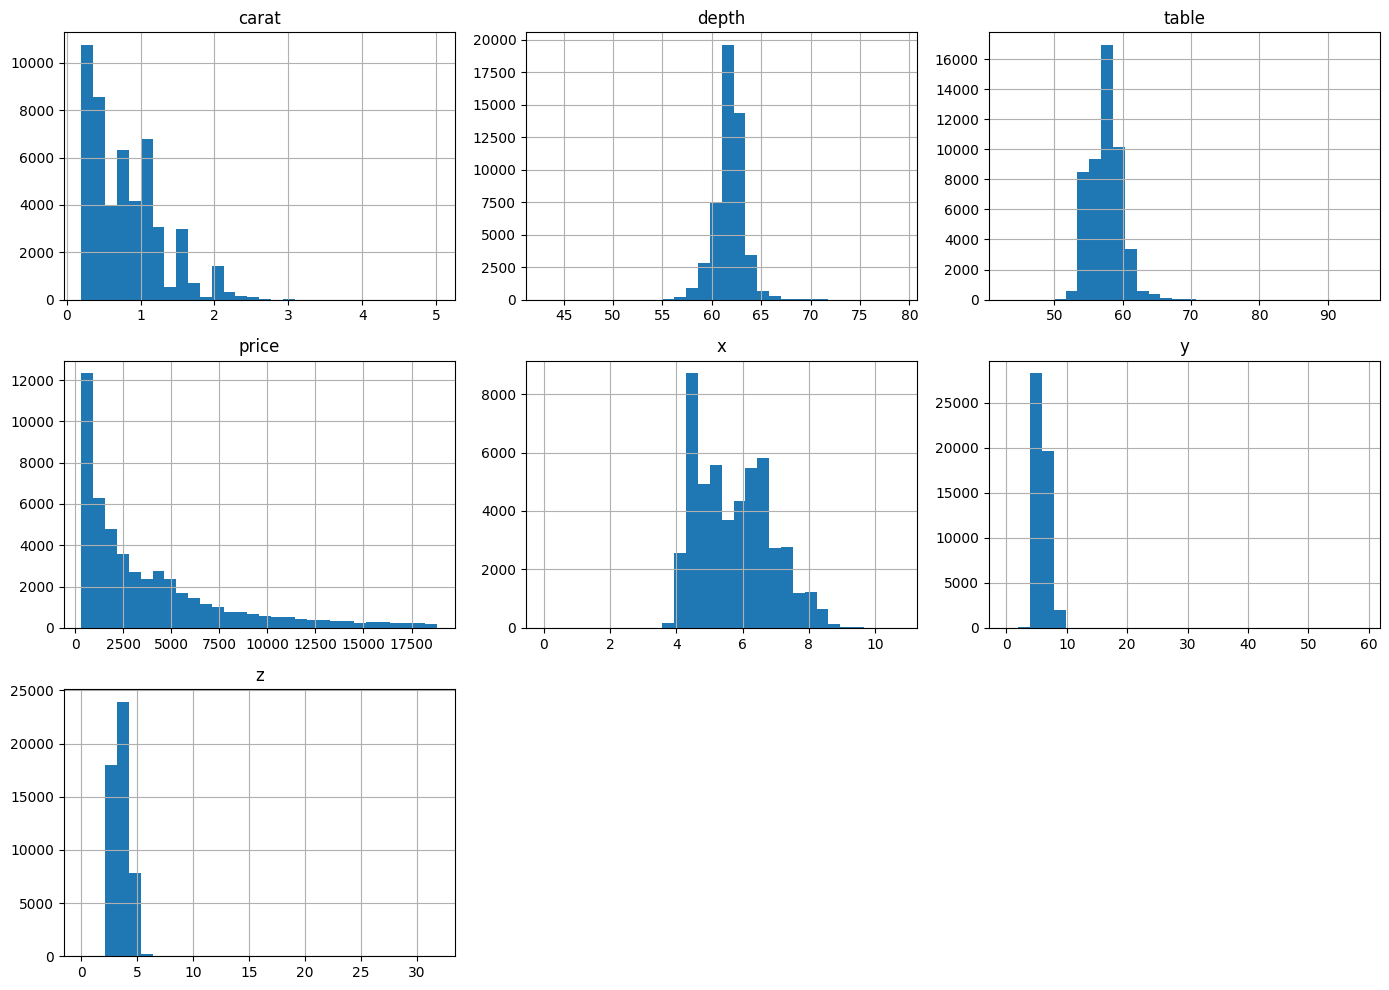

In [58]:
hist_figure(df[columns_with_num])

In [ ]:
# boxplot to visulize the outliers

def boxplot_figure(df, columns):
    for col in columns:
        plt.figure(figsize=(7, 3))
        plt.boxplot(df[col], vert=False)
        plt.title(f"Boxplot of {col}")
        plt.show()

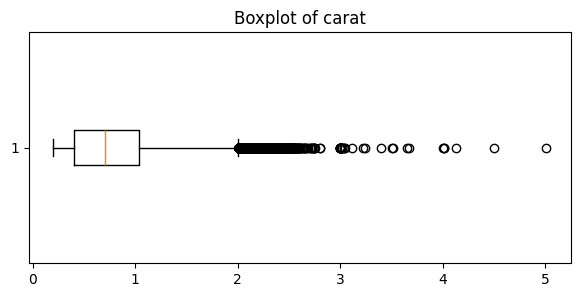

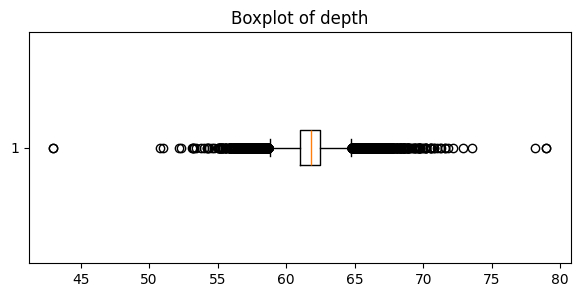

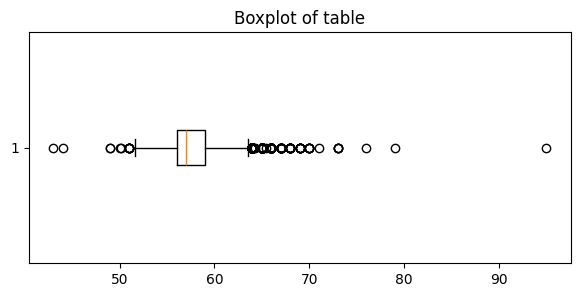

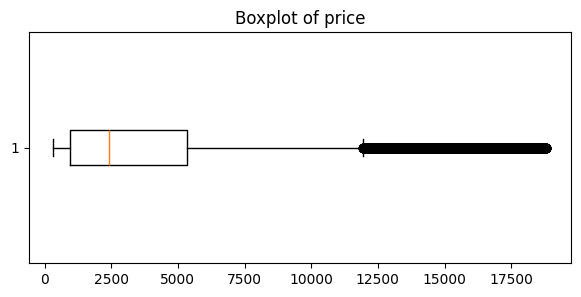

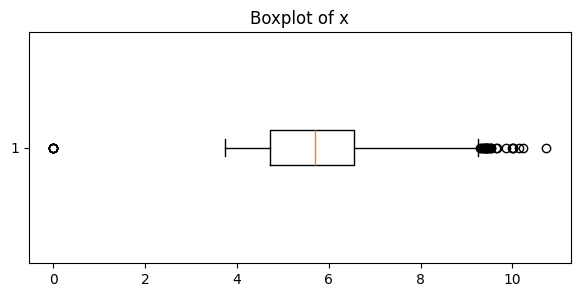

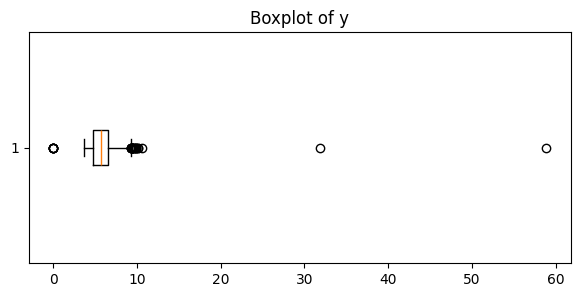

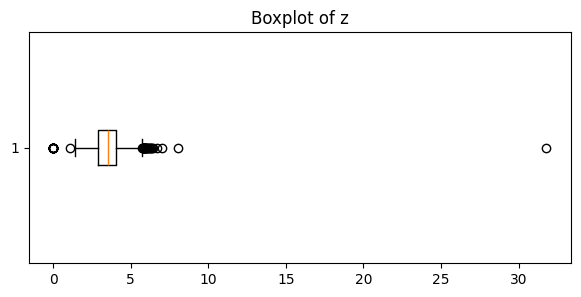

In [55]:
boxplot_figure(df, columns_with_num)

In [64]:
# function to visualize column vs given columns 

def scater_figure(df, columns, vs_column):
    for col in columns:
        plt.figure(figsize=(6, 4))
        plt.scatter(df[col], df[vs_column], alpha=0.3)
        plt.xlabel(col)
        plt.ylabel({vs_column})
        plt.title(f"{col} vs {vs_column}")
        plt.show()

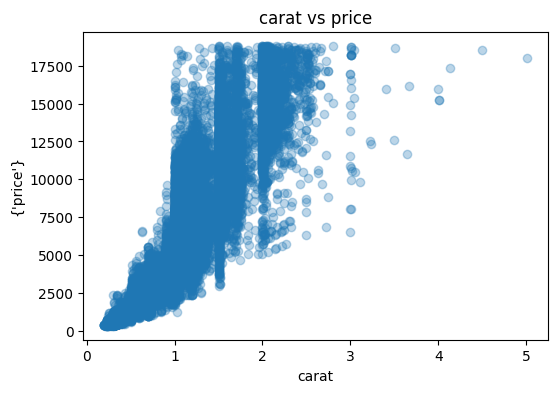

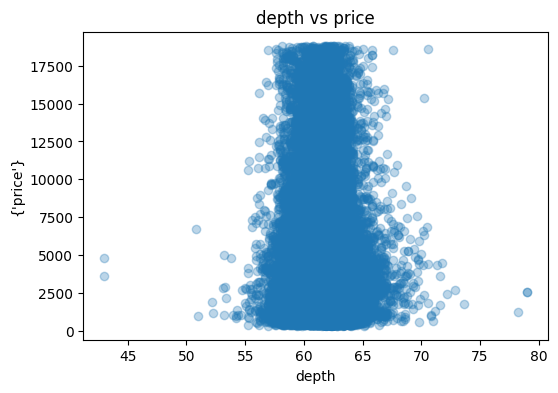

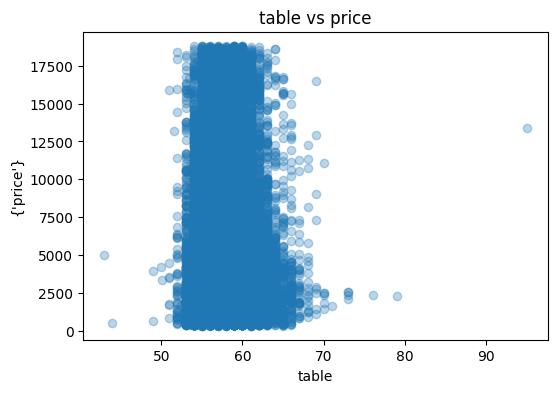

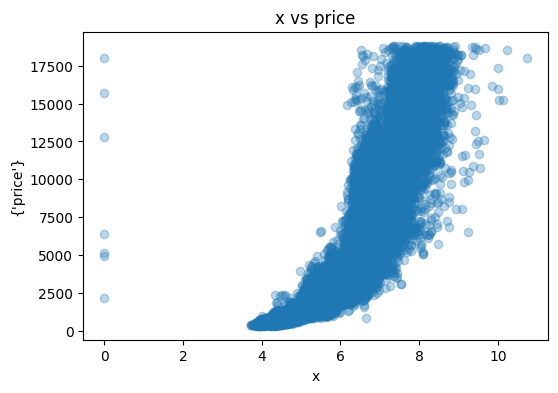

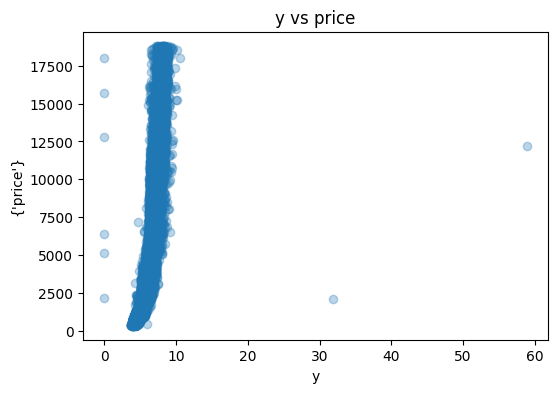

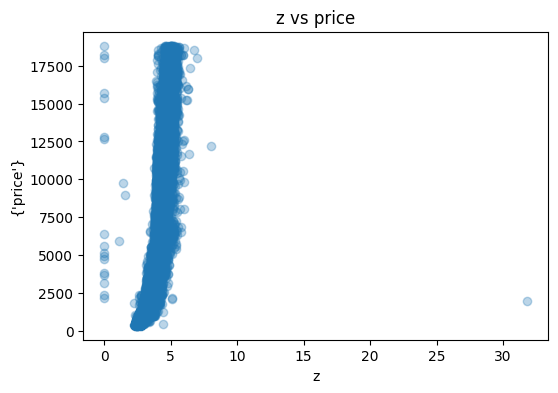

In [65]:
scater_figure(df, ["carat", "depth", "table", "x", "y", "z"], 'price')